# 손목 Depth 카메라 YOLO26n-seg 8 class training + pose 계산

- 클래스 8개 = 색 × 모양 × 서있음/누움: `red_cyl_up … green_box_lying` (`scripts/sim_to_seg.py --classes 8`)
- 데이터: `datasets/sim_wrist` (`make_wrist_dataset.py`, 브래킷 −30°~−2° 무작위 · 미로 9종 · 그리퍼 가림 · 오탐 파란 퍽) → `datasets/sim_seg`
- 학습 weight: `yolo26n-seg.pt` 이용 (`scripts/train.py --stage sim`)
- 자세 = seg 마스크 + 깊이 + 중력 → `scripts/wrist_detector.py` (태그는 ID 만)
- 셀 순서: 0 설정 → 1 라벨 변환 → 2 학습 → 3 TensorBoard → 4 그래프 → 5 test 평가 → 6 예측 그림 → 7 conf 기준값 → 8 오검출 상위 → 9 자세 · 파이프라인 평가

## 0. 설정

In [1]:
import csv, datetime, json, os, random, re, subprocess, sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import yaml

plt.rcParams['font.family'] = ['Noto Sans CJK KR', 'NanumGothic', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
HERE = Path.cwd().resolve()
WRIST_DIR = next(p for p in [HERE, *HERE.parents] if (p / 'scripts' / 'sim_to_seg.py').exists())   # 노트북을 어디서 열어도 yolo/wrist/ 를 찾음
SCRIPTS, CONFIGS, RUNS, DATA = (WRIST_DIR / d for d in ('scripts', 'configs', 'runs', 'datasets'))
sys.path.insert(0, str(SCRIPTS))
PY = sys.executable                  # 이 커널의 파이썬으로 스크립트 실행

SIM = DATA / 'sim_wrist'          # make_wrist_dataset.py 출력
SEG = DATA / 'sim_seg'            # sim_to_seg.py 출력 (8클래스)
PREFIX = ''                          # seg 라벨 파일 이름 앞 (여러 생성 폴더를 합칠 때만 씀)
REBUILD = False                      # True = 라벨 폴더 지우고 다시 만듦
NAME = 'seg8_sim'                    # 결과 runs/wrist/<NAME>
EXTRA_ARGS = []                      # train.py 에 더 줄 인자. 예: ['--epochs', '5', '--batch', '8']
RUN_DIR = None                       # 학습 안 하고 기존 결과만 볼 때: RUNS / 'wrist' / NAME
IMGSZ = yaml.safe_load((CONFIGS / 'hyp.yaml').read_text())['common']['imgsz']
print('yolo/wrist:', WRIST_DIR, '| python:', PY, '| imgsz:', IMGSZ, '| 생성 데이터 장 수:', len(list(SIM.glob('*/*_meta.json'))))

yolo/wrist: /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist | python: /home/jje5976/Desktop/physical_ai/.venvs/yolo/bin/python | imgsz: 640 | 생성 데이터 장 수: 7539


In [2]:
ANSI = re.compile(r'\x1b\[[0-9;]*[A-Za-z]')


def run_logged(cmd, log_path, cwd=SCRIPTS):
    """명령 실행 -> 출력을 셀에 바로 보여주고 log_path 에도 씀. train.py 마지막 줄('끝. 결과: ...')의 결과 폴더를 돌려줌."""
    log_path = Path(log_path)
    log_path.parent.mkdir(parents=True, exist_ok=True)
    print('$', ' '.join(map(str, cmd)), '\n로그:', log_path, flush=True)
    save_dir = None
    env = {**os.environ, 'PYTHONUNBUFFERED': '1'}
    # 바이트로 읽음: 텍스트 모드는 \r 도 줄바꿈으로 바꿔서 진행 막대가 갱신마다 한 줄씩 찍힘 (배치마다 1줄)
    with open(log_path, 'w') as f, subprocess.Popen([str(c) for c in cmd], cwd=cwd, env=env,
                                                    stdout=subprocess.PIPE, stderr=subprocess.STDOUT) as p:
        for raw in p.stdout:                      # b'\n' 단위. 진행 막대는 \r 로 덮어쓰다 끝날 때 \n
            parts = [s for s in raw.decode('utf-8', 'replace').rstrip('\n').split('\r') if s.strip()]
            line = ANSI.sub('', parts[-1] if parts else '')     # 마지막 상태만 (에폭마다 train 1줄 + val 1줄)
            print(line, flush=True)
            f.write(line + '\n')
            if line.startswith('끝. 결과:'):
                save_dir = Path(line.split(':', 1)[1].split('#')[0].strip())
        rc = p.wait()
    if rc:
        raise RuntimeError(f'종료 코드 {rc}. 로그: {log_path}')
    return save_dir

## 1. 라벨 변환 (8클래스 seg)
`sim_to_seg.py --classes 8` → `sim_seg` (`check.jpg` 로 확인, 학습 설정 `sim_seg/data.yaml` 도 같이 만듦). 데이터가 바뀌었을 때만

$ /home/jje5976/Desktop/physical_ai/.venvs/yolo/bin/python sim_to_seg.py --sim /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/datasets/sim_wrist --out /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/datasets/sim_seg --prefix v3_ --classes 8 --check 4 
로그: /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/runs/logs/sim_to_seg8_1029_1424.log
이미지 7539, 퍽 라벨 15533, 작아서 뺀 퍽 274 -> /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/datasets/sim_seg
클래스별 (이번 실행): {'red_cyl_up': 2263, 'green_cyl_up': 2136, 'red_box_up': 2096, 'green_box_up': 2269, 'red_cyl_lying': 1624, 'green_cyl_lying': 1718, 'red_box_lying': 1789, 'green_box_lying': 1638}
그림: /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/datasets/sim_seg/check.jpg
$ /home/jje5976/Desktop/physical_ai/.venvs/yolo/bin/python prepare_data.py --sim /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Nin

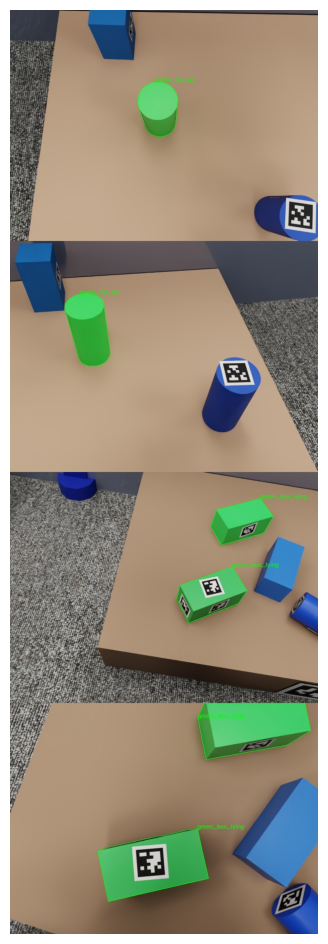

In [3]:
import shutil
ts = datetime.datetime.now().strftime('%m%d_%H%M')
if REBUILD and SEG.exists():
    shutil.rmtree(SEG)
run_logged([PY, 'sim_to_seg.py', '--sim', SIM, '--out', SEG, '--prefix', PREFIX, '--classes', '8', '--check', '4'],
           RUNS / 'logs' / f'sim_to_seg8_{ts}.log')
print((SEG / 'data.yaml').read_text())
# 클래스별 라벨 수 (split 별)
names = yaml.safe_load((SEG / 'data.yaml').read_text())['names']
for sp in ('train', 'val', 'test'):
    cnt = [0] * len(names)
    for f in (SEG / 'labels' / sp).glob('*.txt'):
        for line in f.read_text().splitlines():
            if line.strip():
                cnt[int(line.split()[0])] += 1
    print(f'{sp:<6}', dict(zip(names, cnt)))
plt.figure(figsize=(6, 12)); plt.imshow(cv2.cvtColor(cv2.imread(str(SEG / 'check.jpg')), cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

## 2. 학습
`train.py --stage sim --data datasets/sim_seg/data.yaml --name NAME` (hyp.yaml 설정, `yolo26n-seg.pt` 에서 처음부터). 끝나면 `RUN_DIR` = 결과 폴더

In [4]:
ts = datetime.datetime.now().strftime('%m%d_%H%M')
log = RUNS / 'logs' / f'train_{NAME}_{ts}.log'
RUN_DIR = run_logged([PY, 'train.py', '--stage', 'sim', '--data', SEG / 'data.yaml', '--name', NAME] + list(EXTRA_ARGS), log)
if RUN_DIR:
    (RUN_DIR / 'train.log').write_text(log.read_text())
print('RUN_DIR =', RUN_DIR)

$ /home/jje5976/Desktop/physical_ai/.venvs/yolo/bin/python train.py --stage sim --data /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/configs/data_sim.yaml --name seg8_sim 
로그: /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/runs/logs/train_seg8_sim_1029_1424.log
[train] stage sim, weights yolo26n-seg.pt, data /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/configs/data_sim.yaml
[train] 설정 {'imgsz': 640, 'batch': 24, 'workers': 4, 'optimizer': 'AdamW', 'warmup_bias_lr': 0.0, 'patience': 30, 'seed': 42, 'overlap_mask': True, 'hsv_h': 0.01, 'hsv_s': 0.3, 'hsv_v': 0.3, 'degrees': 10.0, 'translate': 0.1, 'scale': 0.3, 'fliplr': 0.5, 'mosaic': 0.0, 'epochs': 150, 'lr0': 0.0005, 'close_mosaic': 0, 'name': 'seg8_sim', 'augmentations': [PlanckianJitter(p=0.5, mode='blackbody', sampling_method='uniform', temperature_limit=(4000, 8000)), RandomBrightnessContrast(p=0.4, brightness_by_max=True, brightness_limit=(-

## 3. TensorBoard
터미널: `~/Desktop/physical_ai/.venvs/yolo/bin/tensorboard --logdir yolo/wrist/runs/wrist`

In [5]:
%load_ext tensorboard
%tensorboard --logdir {str(RUNS / 'wrist')}

Reusing TensorBoard on port 6007 (pid 2382816), started 18:10:09 ago. (Use '!kill 2382816' to kill it.)

## 4. train · val 지표별 그래프
같은 이름 `train/…` · `val/…` 한 그래프, `metrics/…(B)` = 상자 · `(M)` = 마스크, 학습률

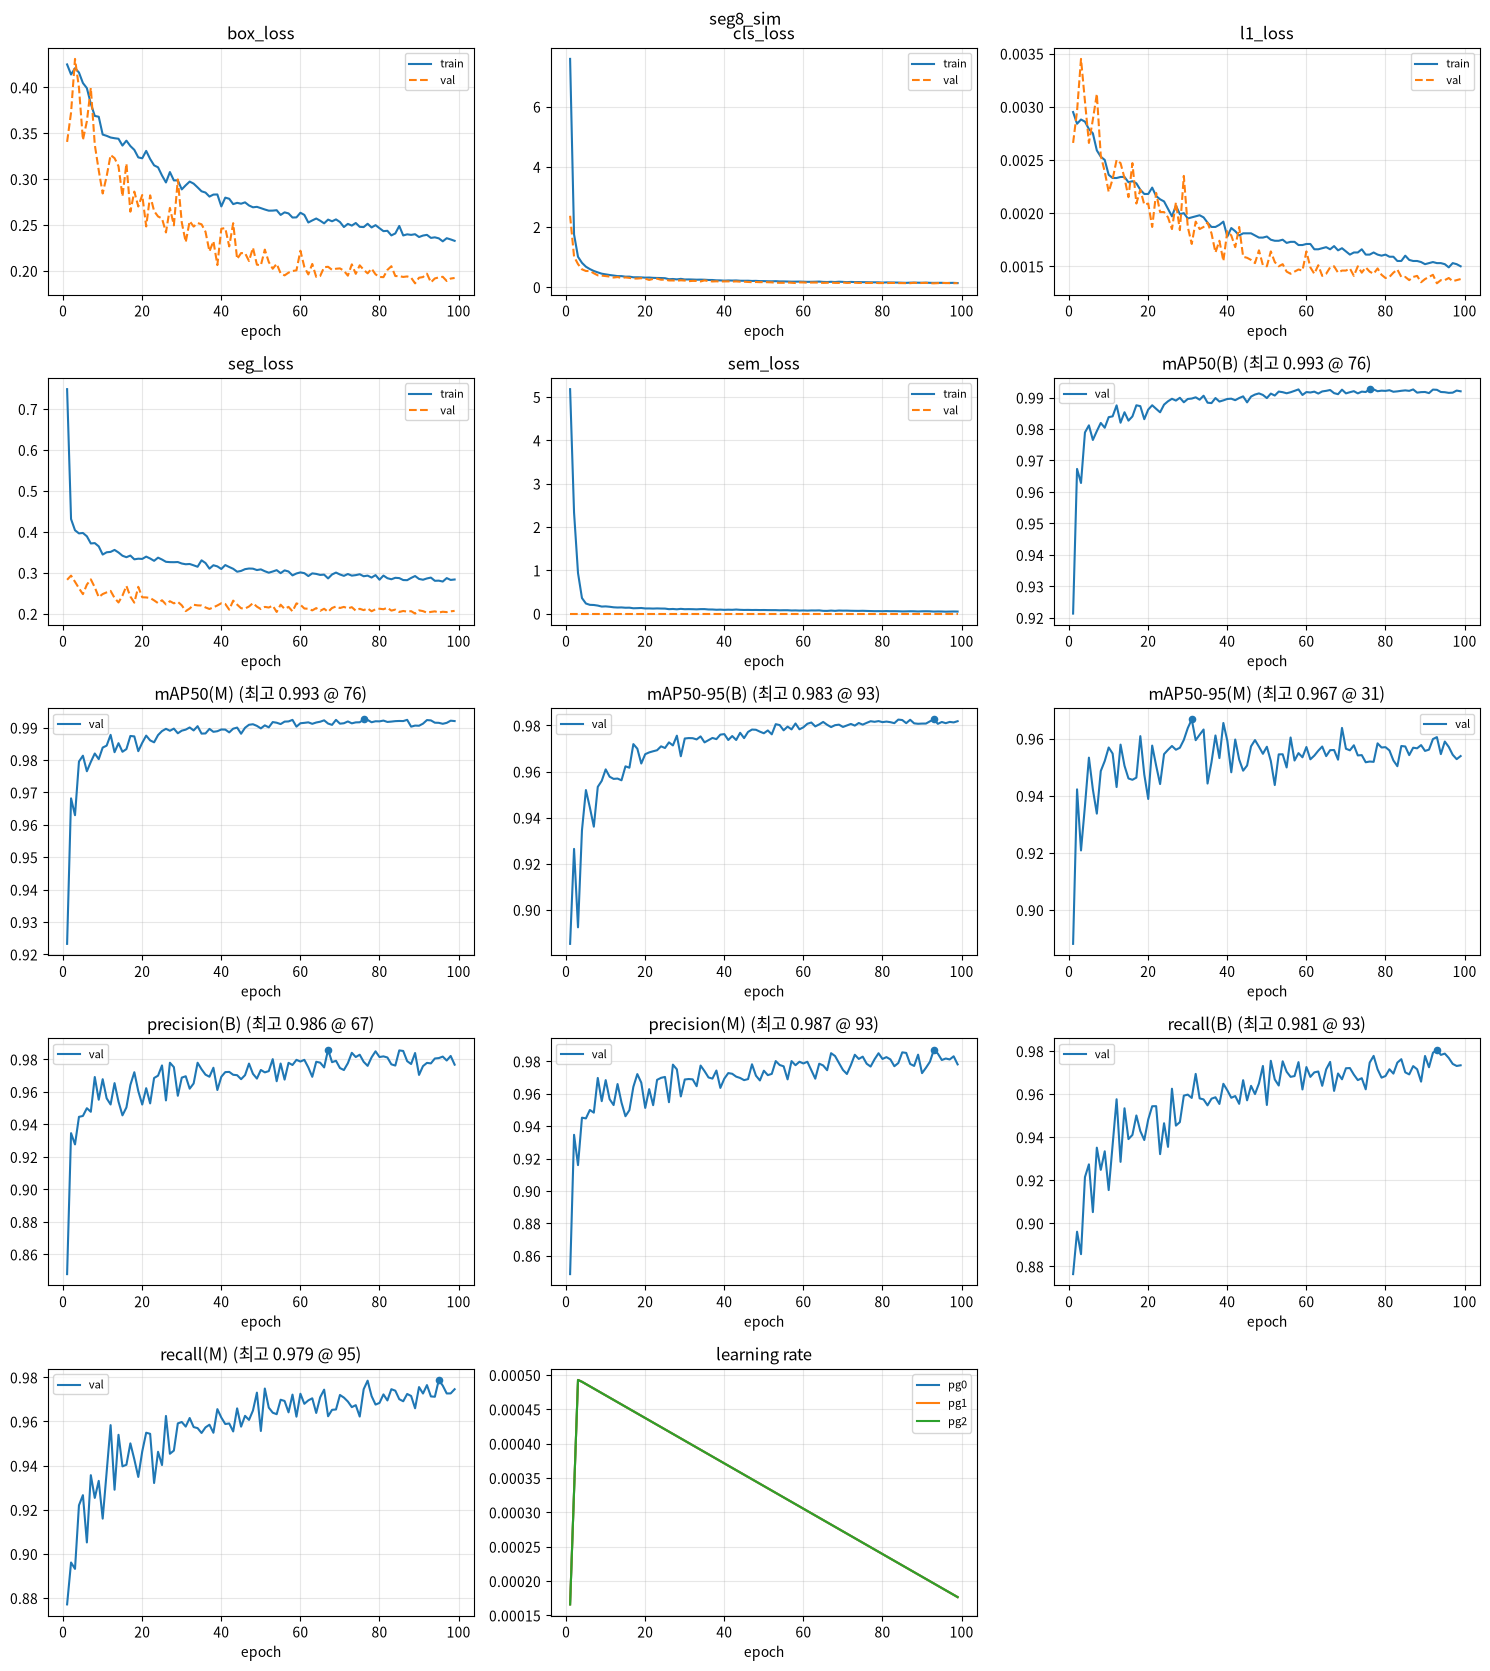

마지막 에폭 99: {'precision(B)': 0.9768, 'recall(B)': 0.9734, 'mAP50(B)': 0.992, 'mAP50-95(B)': 0.9819, 'precision(M)': 0.9781, 'recall(M)': 0.9746, 'mAP50(M)': 0.992, 'mAP50-95(M)': 0.9539}


In [6]:
RUN_DIR = Path(RUN_DIR or RUNS / "wrist" / NAME)
def read_results(run_dir):
    with open(Path(run_dir) / 'results.csv') as f:
        rows = list(csv.DictReader(f))
    cols = {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}
    return cols


def plot_curves(run_dir):
    c = read_results(run_dir)
    ep = c.pop('epoch')
    loss_names = sorted({k.split('/', 1)[1] for k in c if k.startswith(('train/', 'val/'))})
    metric_names = sorted(k for k in c if k.startswith('metrics/'))
    lr_names = sorted(k for k in c if k.startswith('lr/'))
    panels = [('loss', n) for n in loss_names] + [('metric', n) for n in metric_names] + ([('lr', None)] if lr_names else [])
    ncol = 3
    nrow = (len(panels) + ncol - 1) // ncol
    fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 3.4 * nrow), squeeze=False)
    for ax, (kind, n) in zip(axes.flat, panels):
        if kind == 'loss':
            for split, sty in (('train', '-'), ('val', '--')):
                if f'{split}/{n}' in c:
                    ax.plot(ep, c[f'{split}/{n}'], sty, label=split)
            ax.set_title(n)
        elif kind == 'metric':
            ax.plot(ep, c[n], label='val')
            best = int(np.argmax(c[n]))
            ax.scatter([ep[best]], [c[n][best]], s=20, zorder=3)
            ax.set_title(f'{n.split("/", 1)[1]} (최고 {c[n][best]:.3f} @ {int(ep[best])})')
        else:
            for k in lr_names:
                ax.plot(ep, c[k], label=k.split('/', 1)[1])
            ax.set_title('learning rate')
        ax.set_xlabel('epoch')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    for ax in list(axes.flat)[len(panels):]:
        ax.axis('off')
    fig.suptitle(Path(run_dir).name)
    fig.tight_layout()
    fig.savefig(Path(run_dir) / 'train_val_curves.png', dpi=120)
    plt.show()
    last = {k: float(v[-1]) for k, v in c.items() if k.startswith('metrics/')}
    print(f'마지막 에폭 {int(ep[-1])}:', {k.split('/', 1)[1]: round(v, 4) for k, v in last.items()})


plot_curves(RUN_DIR)

## 5. test 평가
`best.pt` 로 test 평가 (클래스 8개별 상자 · 마스크 지표). `sim_seg` 시뮬 test (합성 데이터만 씀) → **시뮬 점수는 실물 성능이 아님**

In [7]:
from ultralytics import YOLO

BEST = Path(RUN_DIR) / 'weights' / 'best.pt'
model = YOLO(str(BEST))
TEST_YAML = SEG / 'data.yaml'        # 학습 데이터와 같은 sim_seg 의 test split
m = model.val(data=str(TEST_YAML), split='test', imgsz=IMGSZ, batch=8, conf=0.001, plots=True,
              project=str(RUNS / 'eval'), name=f'{Path(RUN_DIR).name}_test', exist_ok=True, verbose=False)
print('test:', yaml.safe_load(TEST_YAML.read_text())['test'])
print(f'상자   mAP50 {m.box.map50:.3f}  mAP50-95 {m.box.map:.3f}')
print(f'마스크 mAP50 {m.seg.map50:.3f}  mAP50-95 {m.seg.map:.3f}')
print(f'{"클래스":<12}{"상자 P":>8}{"R":>7}{"mAP50":>8}{"마스크 P":>10}{"R":>7}{"mAP50":>8}{"50-95":>8}')
for i, c in enumerate(m.seg.ap_class_index):
    bp, br, b50, _ = m.box.class_result(i)
    sp, sr, s50, s = m.seg.class_result(i)
    print(f'{m.names[int(c)]:<12}{bp:8.3f}{br:7.3f}{b50:8.3f}{sp:10.3f}{sr:7.3f}{s50:8.3f}{s:8.3f}')
print('속도 (ms/장):', {k: round(v, 1) for k, v in m.speed.items()})
print('그림:', m.save_dir)

Ultralytics 8.4.185 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)
YOLO26n-seg summary (fused): 137 layers, 2,705,484 parameters, 0 gradients, 9.2 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.1 ms, read: 675.5±229.7 MB/s, size: 429.9 KB)
val: Scanning /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/datasets/sim_seg/labels/test... 771 images, 42 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 771/771 1.1Kit/s 0.7s<0.0s
val: New cache created: /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/datasets/sim_seg/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 97/97 25.1it/s 3.9s0.1s
                   all        771       1562      0.982      0.968      0.993      0.981      0.983      0.969      0.993      0.958
Speed: 0.4ms preprocess, 2.3ms inference, 0.0ms loss, 0.5ms postprocess

In [13]:
from ultralytics import YOLO

BEST = Path(RUN_DIR) / 'weights' / 'last.pt'
model = YOLO(str(BEST))
TEST_YAML = SEG / 'data.yaml'        # 학습 데이터와 같은 sim_seg 의 test split
m = model.val(data=str(TEST_YAML), split='test', imgsz=IMGSZ, batch=8, conf=0.001, plots=True,
              project=str(RUNS / 'eval'), name=f'{Path(RUN_DIR).name}_test', exist_ok=True, verbose=False)
print('test:', yaml.safe_load(TEST_YAML.read_text())['test'])
print(f'상자   mAP50 {m.box.map50:.3f}  mAP50-95 {m.box.map:.3f}')
print(f'마스크 mAP50 {m.seg.map50:.3f}  mAP50-95 {m.seg.map:.3f}')
print(f'{"클래스":<12}{"상자 P":>8}{"R":>7}{"mAP50":>8}{"마스크 P":>10}{"R":>7}{"mAP50":>8}{"50-95":>8}')
for i, c in enumerate(m.seg.ap_class_index):
    bp, br, b50, _ = m.box.class_result(i)
    sp, sr, s50, s = m.seg.class_result(i)
    print(f'{m.names[int(c)]:<12}{bp:8.3f}{br:7.3f}{b50:8.3f}{sp:10.3f}{sr:7.3f}{s50:8.3f}{s:8.3f}')
print('속도 (ms/장):', {k: round(v, 1) for k, v in m.speed.items()})
print('그림:', m.save_dir)

Ultralytics 8.4.185 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)
YOLO26n-seg summary (fused): 137 layers, 2,705,484 parameters, 0 gradients, 9.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6086.7±1229.1 MB/s, size: 435.1 KB)
val: Scanning /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/datasets/sim_seg/labels/test.cache... 771 images, 42 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 771/771 462.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 97/97 24.3it/s 4.0s0.1s
                   all        771       1562      0.981      0.972      0.993      0.981      0.981      0.972      0.992      0.947
Speed: 0.6ms preprocess, 2.1ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/runs/eval/seg8_sim_test
te

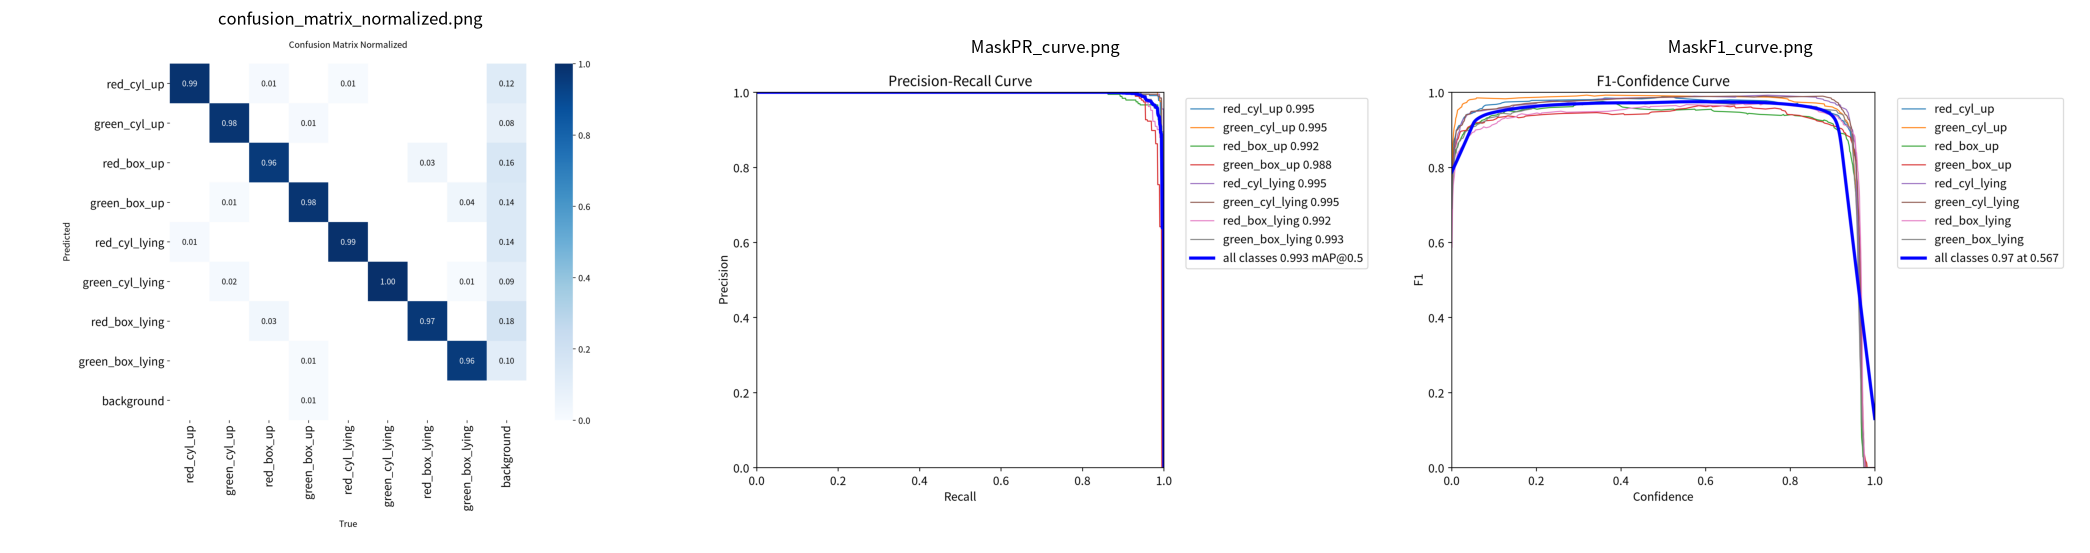

In [8]:
figs = [f for f in ('confusion_matrix_normalized.png', 'MaskPR_curve.png', 'MaskF1_curve.png') if (Path(m.save_dir) / f).exists()]
fig, axes = plt.subplots(1, len(figs), figsize=(7 * len(figs), 6), squeeze=False)
for ax, f in zip(axes.flat, figs):
    ax.imshow(plt.imread(Path(m.save_dir) / f))
    ax.set_title(f)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 6. test 이미지 시각화
무작위 `N_SHOW` 장. 정답 다각형 = 초록 윤곽, 예측 = 반투명 마스크 + 클래스 · 신뢰도

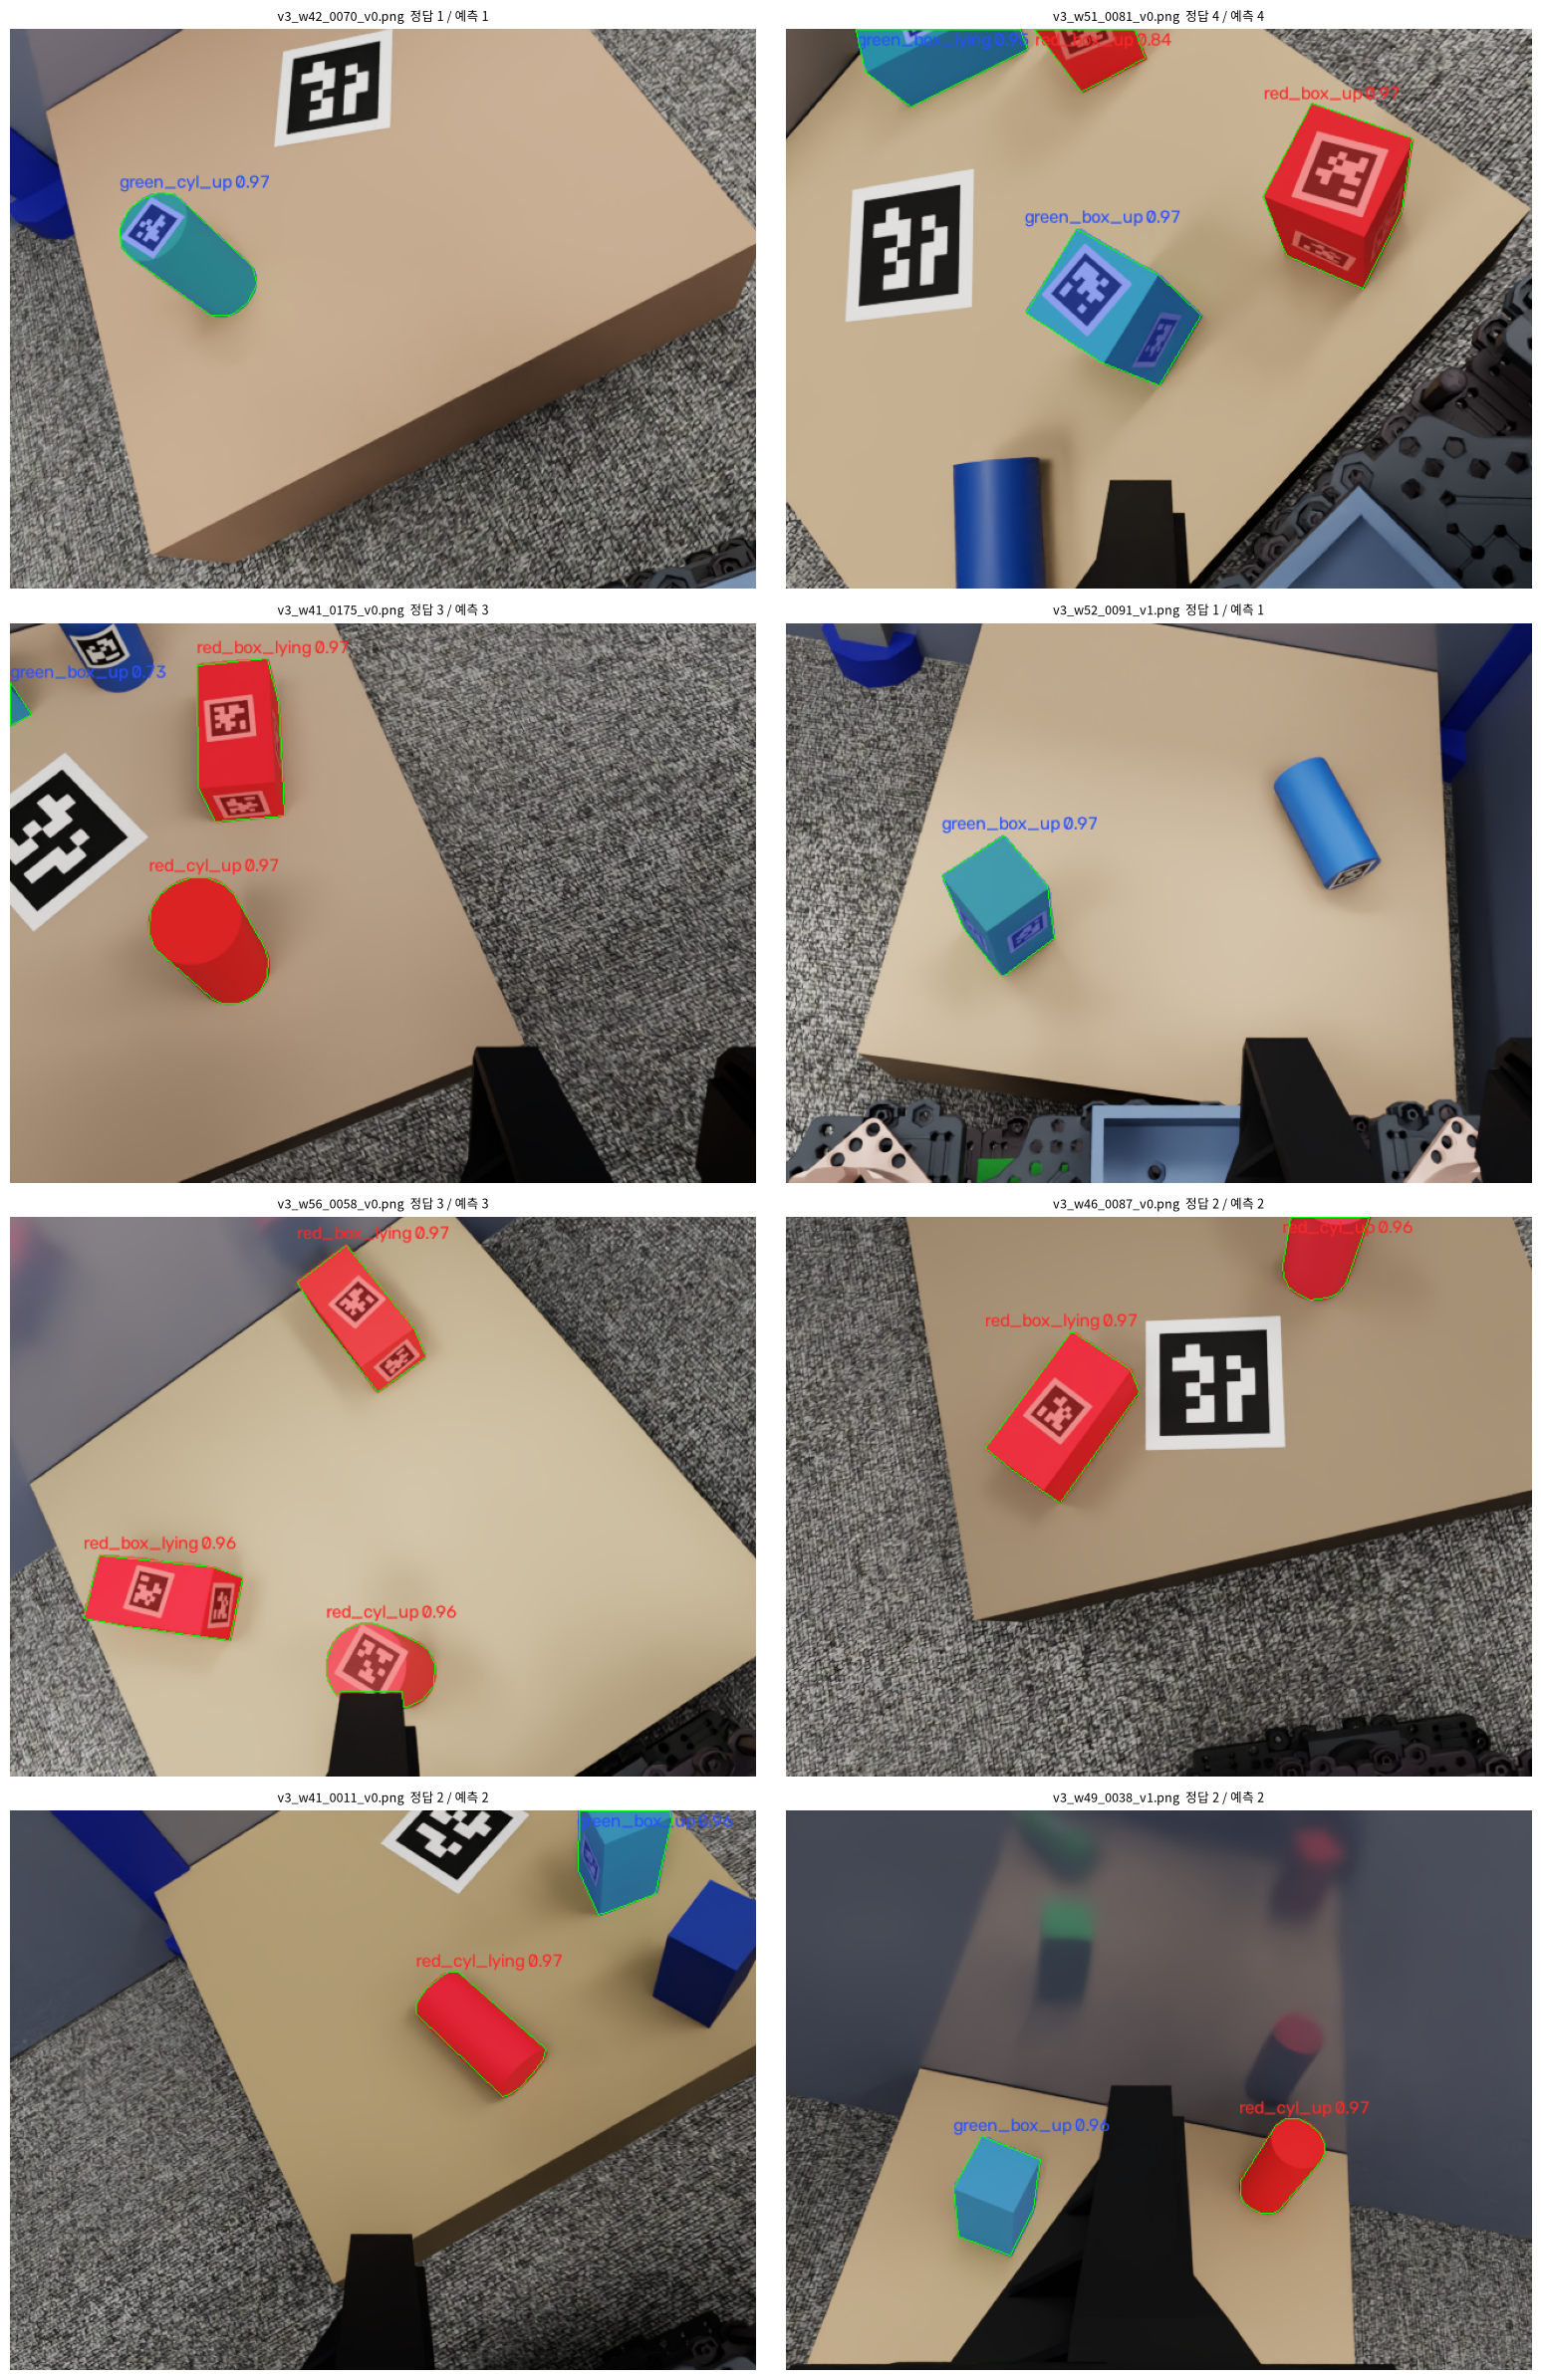

In [9]:
N_SHOW, CONF, SEED = 8, 0.25, 0

test_src = yaml.safe_load(Path(TEST_YAML).read_text())['test']
test_dirs = [Path(t) if Path(t).is_absolute() else Path(TEST_YAML).parent / t for t in (test_src if isinstance(test_src, list) else [test_src])]
imgs = sorted(p for d_ in test_dirs for p in d_.glob('*') if p.suffix.lower() in ('.jpg', '.jpeg', '.png'))
random.Random(SEED).shuffle(imgs)
imgs = imgs[:N_SHOW]


def gt_polys(img_path, w, h):
    lab = Path(str(img_path).replace('/images/', '/labels/')).with_suffix('.txt')
    out = []
    if lab.exists():
        for line in lab.read_text().split('\n'):
            if line.strip():
                v = list(map(float, line.split()))
                out.append((int(v[0]), (np.array(v[1:]).reshape(-1, 2) * [w, h]).astype(np.int32)))
    return out


ncol = 2
fig, axes = plt.subplots((len(imgs) + ncol - 1) // ncol, ncol, figsize=(8 * ncol, 6 * ((len(imgs) + ncol - 1) // ncol)), squeeze=False)
for ax, p, r in zip(axes.flat, imgs, model.predict([str(x) for x in imgs], conf=CONF, imgsz=IMGSZ, retina_masks=True, verbose=False)):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    gts = gt_polys(p, w, h)
    if r.masks is not None:
        for mk, c, s, (x0, y0, x1, y1) in zip(r.masks.data.cpu().numpy() > 0.5, r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist()):
            col = np.array((255, 40, 40) if r.names[int(c)].startswith('red') else (40, 80, 255))
            im[mk] = (0.55 * im[mk] + 0.45 * col).astype(np.uint8)
            cv2.putText(im, f'{r.names[int(c)]} {s:.2f}', (int(x0), max(14, int(y0) - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, tuple(int(v) for v in col), 1)
    for c, poly in gts:
        cv2.polylines(im, [poly], True, (0, 255, 0), 1)
    ax.imshow(im)
    ax.set_title(f'{p.name}  정답 {len(gts)} / 예측 {0 if r.masks is None else len(r.masks)}', fontsize=9)
    ax.axis('off')
for ax in list(axes.flat)[len(imgs):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 7. conf 기준값별 오탐 · 놓침
기준값마다 TP · 클래스 틀림 · FP(오탐 또는 라벨 누락) · FN(놓침). 8클래스라 **클래스 틀림에는 선/누움 혼동도 포함**됨. 데이터 = `sim_seg` (시뮬)

가중치: /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/runs/wrist/seg8_sim/weights/best.pt | 데이터: /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/datasets/sim_seg ⚠ 시뮬 결과 = 실제 기준값 아님

== sim_seg val: 746장, 정답 1544개
 conf    TP   클래스틀림   FP   FN  precision  recall
 0.10  1504      36   72    4      0.933   0.974
 0.25  1502      35   39    7      0.953   0.973
 0.40  1499      34   23   11      0.963   0.971
 0.50  1495      31   14   18      0.971   0.968
 0.60  1488      22    4   34      0.983   0.964
 0.70  1470      16    1   58      0.989   0.952
 0.80  1453      10    0   81      0.993   0.941
 0.85  1432       6    0  106      0.996   0.927
 0.90  1388       2    0  154      0.999   0.899
맞은 예측 점수 10 / 25 / 50%: [      0.917       0.952       0.961]
FP 점수 상위: [       0.77        0.67        0.65       0.608       0.589       0.587       0.577       0.557]

== sim_seg test: 771장, 정답 1562개
 conf    TP   클래스틀림   FP   FN  precisi

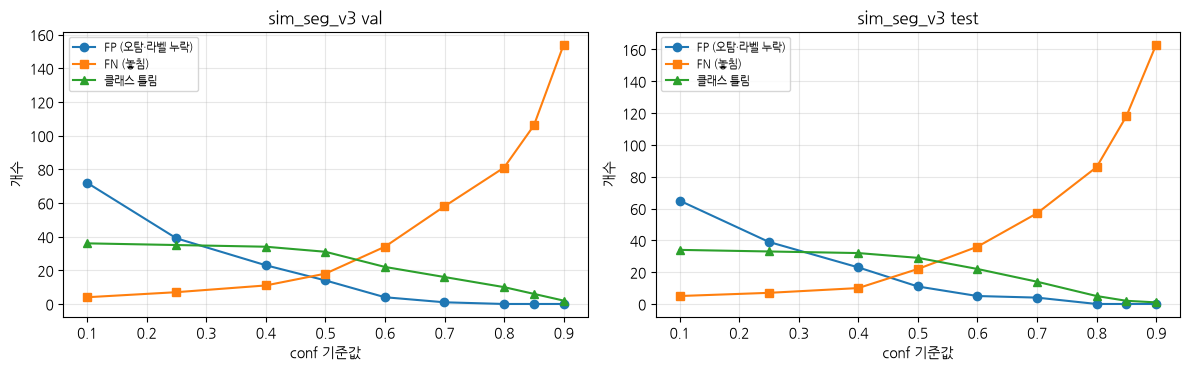

In [10]:
import gc
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from ultralytics import YOLO
from ultralytics.utils.metrics import box_iou

plt.rcParams['font.family'] = ['NanumGothic', 'Noto Sans CJK KR', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

CS_SPLITS = ('val', 'test')                     # 계산할 split
CS_THRESHOLDS = (0.1, 0.25, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9)
CS_IOU, CS_BATCH = 0.45, 8                      # 정답 매칭 기준 상자 IoU, 한 번에 predict 할 장 수
CS_DATA = 'sim_seg'                             # 시뮬 seg 데이터 (합성만 씀)

cs_here = Path.cwd().resolve()
cs_wrist = next(q for p in [cs_here, *cs_here.parents] for q in (p, p / 'yolo' / 'wrist') if (q / 'scripts/sim_to_seg.py').is_file())
cs_run = Path(globals().get('RUN_DIR') or cs_wrist / 'runs/wrist/seg8_sim')
cs_weights = cs_run / 'weights/best.pt'
cs_imgsz = yaml.safe_load((cs_run / 'args.yaml').read_text()).get('imgsz', 640)
cs_root = cs_wrist / 'datasets' / CS_DATA
print('가중치:', cs_weights, '| 데이터:', cs_root, '⚠ 시뮬 결과 = 실물 기준값 아님')

gc.collect()
cs_cuda = torch.cuda.is_available()
if cs_cuda:
    torch.cuda.empty_cache()
cs_model = YOLO(str(cs_weights))


def cs_collect(split):
    """split 전체 예측 → preds [(점수, 정답과 매칭됨, 클래스 맞음)], 정답마다 매칭된 예측 점수(없으면 0)"""
    ims = sorted(p for p in (cs_root / 'images' / split).glob('*') if p.suffix.lower() in ('.png', '.jpg', '.jpeg'))
    preds, gt_best = [], []
    for s in range(0, len(ims), CS_BATCH):
        with torch.inference_mode():
            results = cs_model.predict([str(p) for p in ims[s:s + CS_BATCH]], conf=min(CS_THRESHOLDS), imgsz=cs_imgsz,
                                       iou=0.7, batch=CS_BATCH, quantize=16 if cs_cuda else None, verbose=False, save=False)
        for r in results:
            h, w = r.orig_shape
            lab = Path(str(r.path).replace('/images/', '/labels/')).with_suffix('.txt')
            gts = []
            for line in (lab.read_text().splitlines() if lab.exists() else []):
                if line.strip():
                    v = list(map(float, line.split()))
                    q = np.array(v[1:]).reshape(-1, 2) * [w, h]
                    gts.append((int(v[0]), np.r_[q.min(0), q.max(0)]))
            boxes = r.boxes.xyxy.cpu()
            scores = r.boxes.conf.cpu().numpy()
            classes = r.boxes.cls.cpu().numpy().astype(int)
            if gts and len(boxes):
                ious = box_iou(torch.tensor(np.array([g[1] for g in gts]), dtype=torch.float32), boxes).numpy()
            else:
                ious = np.zeros((len(gts), len(boxes)))
            best = np.zeros(len(gts))
            used = set()
            # 클래스와 무관하게 점수 높은 예측부터 IoU > CS_IOU 정답과 일대일 매칭함
            for j in np.argsort(-scores, kind='stable'):
                k = int(ious[:, j].argmax()) if gts else -1
                if k >= 0 and ious[k, j] > CS_IOU and k not in used:
                    used.add(k)
                    best[k] = scores[j]
                    preds.append((scores[j], True, classes[j] == gts[k][0]))
                else:
                    preds.append((scores[j], False, False))
            gt_best += list(best)
        del results
    return len(ims), np.array(preds, dtype=float).reshape(-1, 3), np.array(gt_best)


cs_tables = {}
for split in CS_SPLITS:
    n_img, P, G = cs_collect(split)
    if n_img == 0:
        print(f'\n{split}: 이미지 없음')
        continue
    rows = []
    for t in CS_THRESHOLDS:
        k = P[:, 0] >= t
        tp = int((k & (P[:, 1] == 1) & (P[:, 2] == 1)).sum())
        wrong = int((k & (P[:, 1] == 1) & (P[:, 2] == 0)).sum())   # 위치는 맞는데 클래스(색·모양) 틀림
        fp = int((k & (P[:, 1] == 0)).sum())                       # 정답 없는 곳 (오탐 또는 라벨 누락)
        fn = int((G < t).sum())                                    # 놓친 정답
        rows.append((t, tp, wrong, fp, fn, tp / max(1, tp + wrong + fp), tp / max(1, len(G))))
    cs_tables[split] = rows
    print(f'\n== {CS_DATA} {split}: {n_img}장, 정답 {len(G)}개')
    print(f'{"conf":>5}{"TP":>6}{"클래스틀림":>8}{"FP":>5}{"FN":>5}{"precision":>11}{"recall":>8}')
    for t, tp, wrong, fp, fn, prec, rec in rows:
        print(f'{t:5.2f}{tp:6d}{wrong:8d}{fp:5d}{fn:5d}{prec:11.3f}{rec:8.3f}')
    tps, fps = P[(P[:, 1] == 1) & (P[:, 2] == 1), 0], P[P[:, 1] == 0, 0]
    if len(tps):
        print('맞은 예측 점수 10 / 25 / 50%:', np.round(np.percentile(tps, [10, 25, 50]), 3))
    print('FP 점수 상위:', np.round(np.sort(fps)[::-1][:8], 3))
if cs_cuda:
    torch.cuda.empty_cache()

if cs_tables:
    fig, axes = plt.subplots(1, len(cs_tables), figsize=(6 * len(cs_tables), 3.8), squeeze=False)
    for ax, (split, rows) in zip(axes.flat, cs_tables.items()):
        t = [r[0] for r in rows]
        ax.plot(t, [r[3] for r in rows], 'o-', label='FP (오탐·라벨 누락)')
        ax.plot(t, [r[4] for r in rows], 's-', label='FN (놓침)')
        ax.plot(t, [r[2] for r in rows], '^-', label='클래스 틀림')
        ax.set_xlabel('conf 기준값')
        ax.set_ylabel('개수')
        ax.set_title(f'{CS_DATA} {split}')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## 8. validation 오검출 후보 상위 10
정답과 IoU 로 안 맞는 예측 (오탐 · 라벨 누락 · 위치 오류)

가중치: /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/runs/wrist/seg8_sim/weights/best.pt
데이터 설정: /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/configs/data_sim.yaml
val 746장 | confidence ≥ 0.25 미매칭 예측 39개


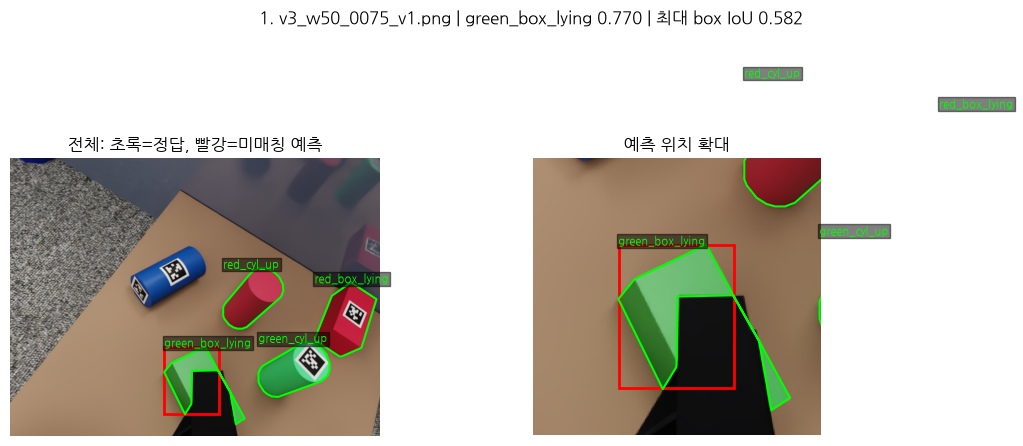

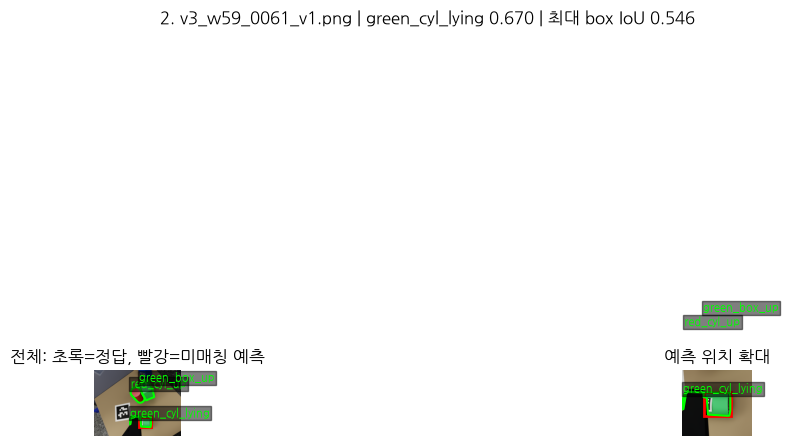

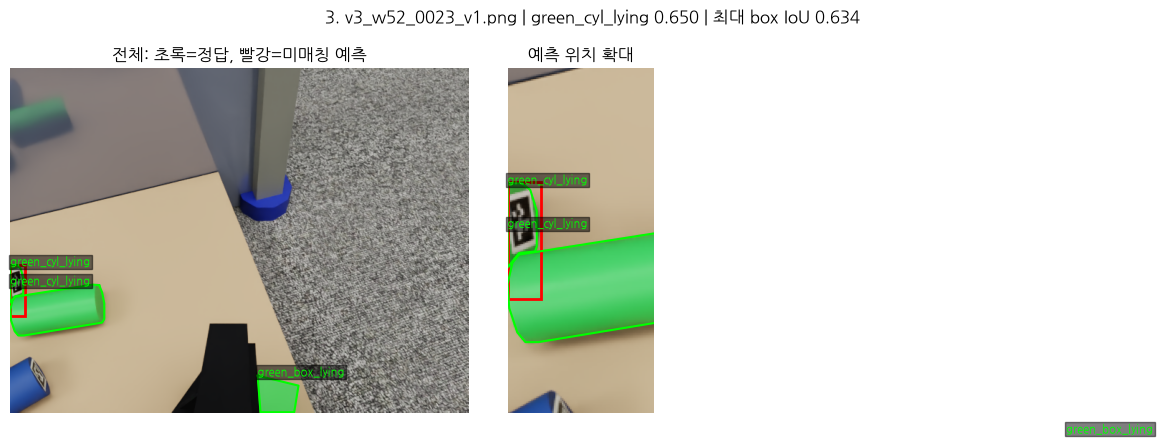

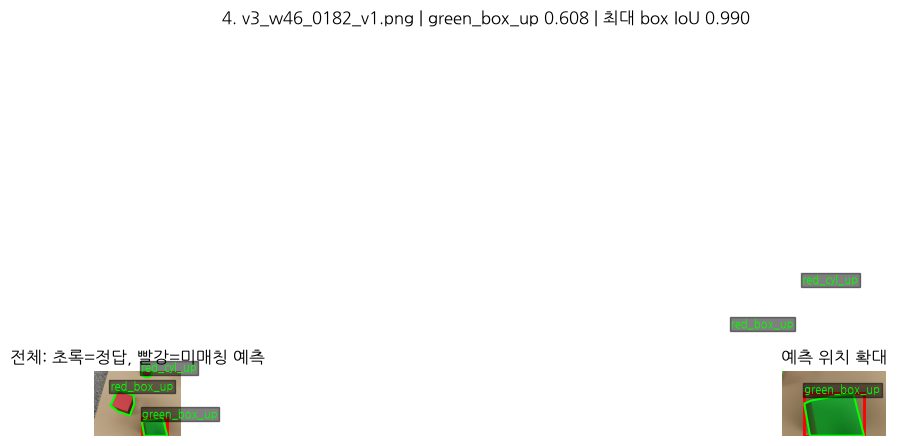

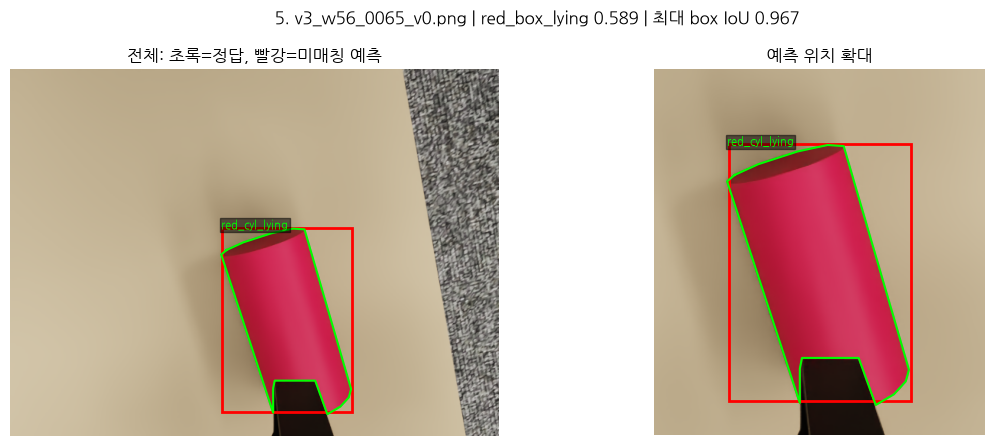

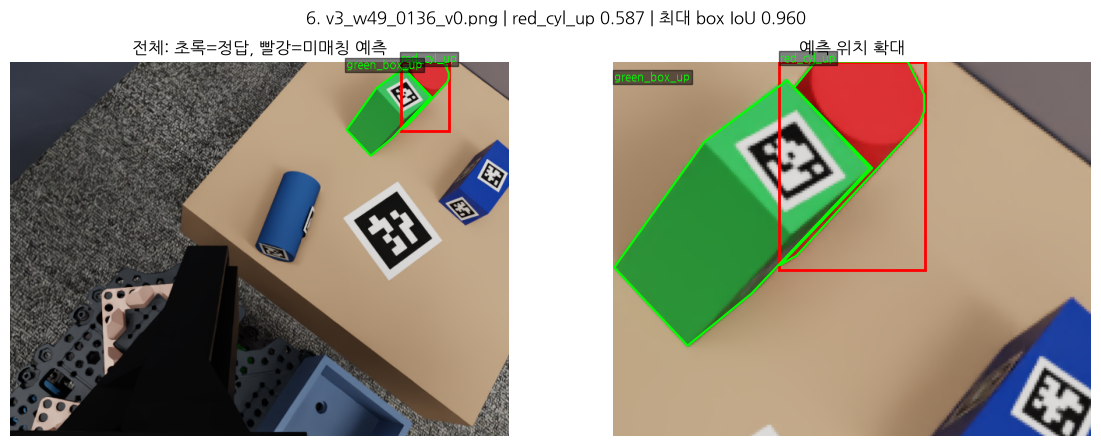

/tmp/ipykernel_3106771/517554062.py:130: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


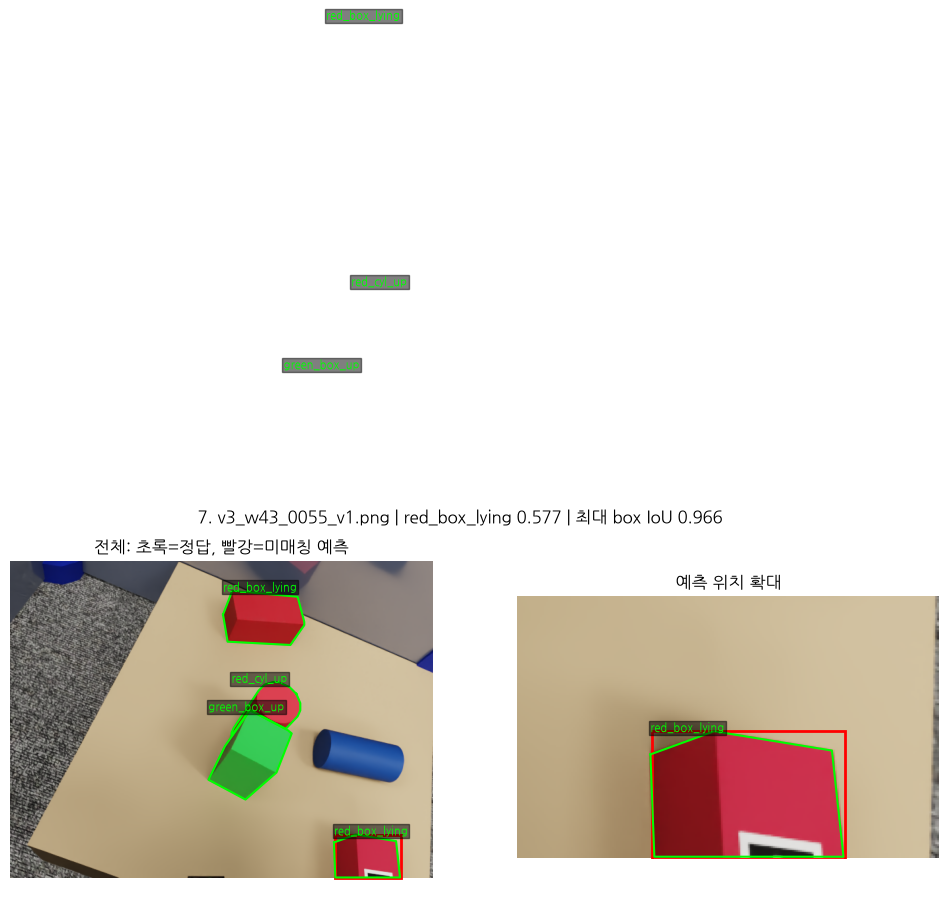

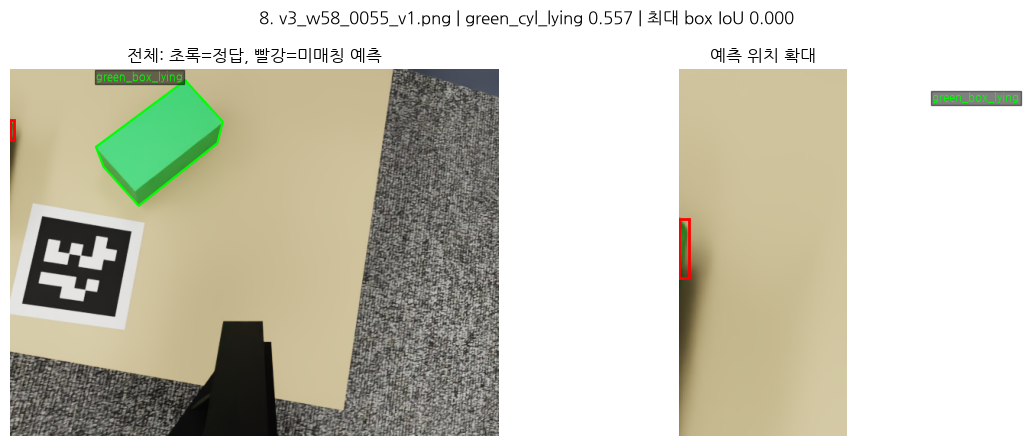

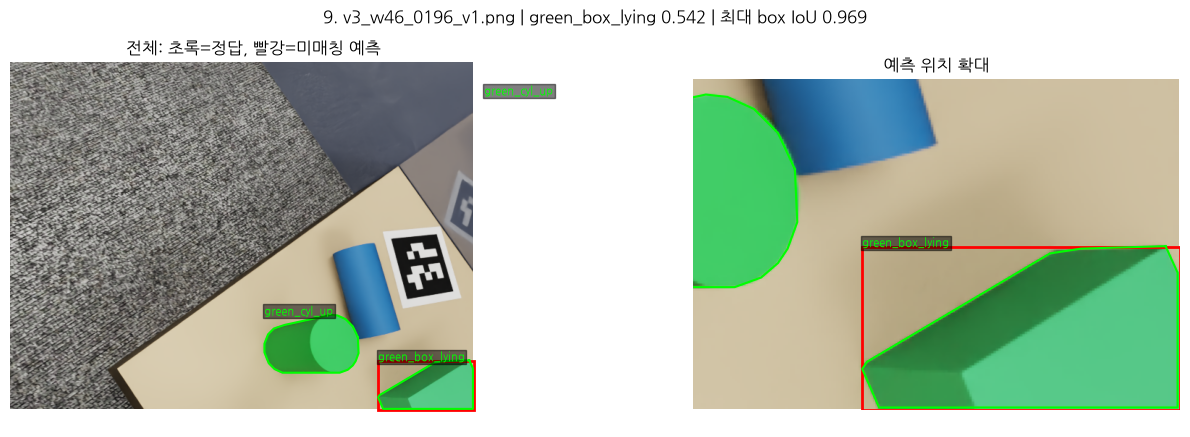

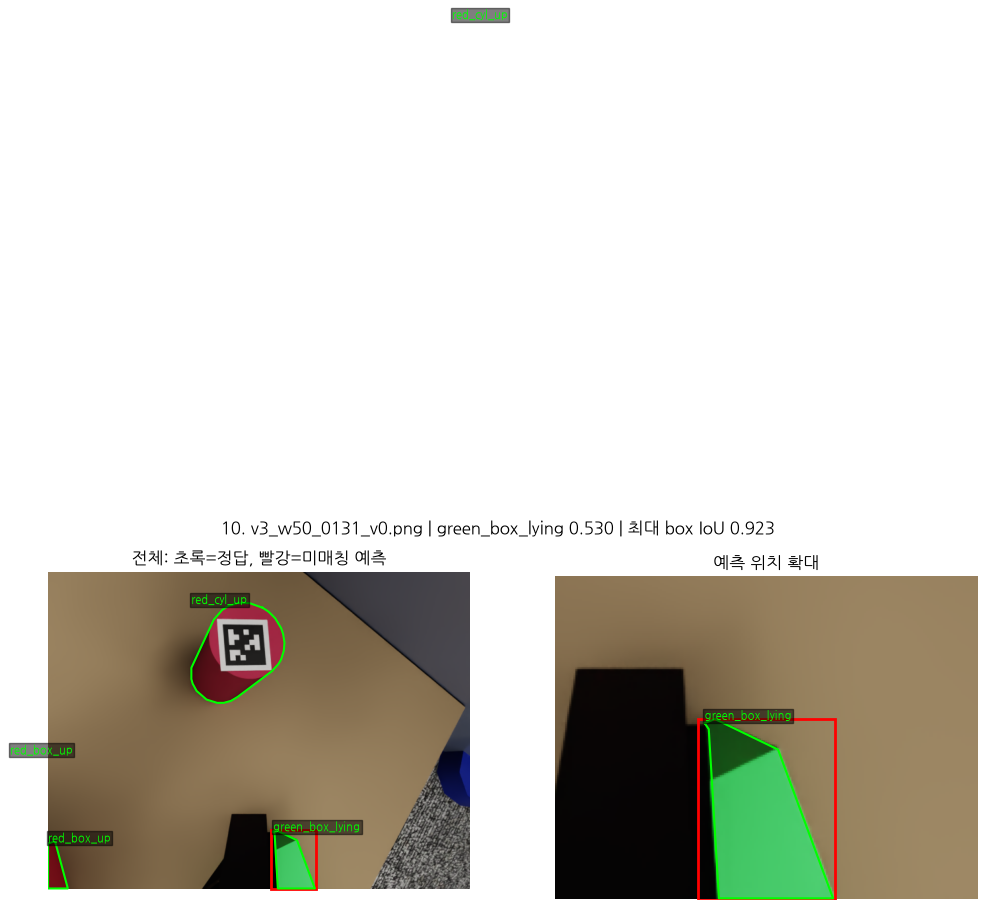

In [11]:
import gc
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from ultralytics import YOLO
from ultralytics.utils.metrics import box_iou

plt.rcParams['font.family'] = ['NanumGothic', 'Noto Sans CJK KR', 'DejaVu Sans']   # 이 셀만 단독 실행해도 한글 나오게
plt.rcParams['axes.unicode_minus'] = False

FP_CONF, FP_TOP_N = 0.25, 10  # 반사 등 낮은 점수도 보려면 0.05로 변경함
FP_BATCH = 8                  # 한 번에 predict 할 장 수. 이미지 리스트를 통째로 넘기면 GPU에서 전부 한 배치로 묶여 메모리 부족 → 나눠서 넘김
# 설정 셀만 실행해서 RUN_DIR=None인 경우 기존 seg8_sim 결과 사용함
fp_here = Path.cwd().resolve()
fp_candidates = [q for p in [fp_here, *fp_here.parents] for q in (p, p / 'yolo' / 'wrist')]
fp_wrist = next((p for p in fp_candidates if (p / 'scripts/sim_to_seg.py').is_file()), None)
if fp_wrist is None:
    raise FileNotFoundError(f'yolo/wrist 폴더를 찾을 수 없음. 현재 실행 위치: {fp_here}')
fp_run = Path(globals().get('RUN_DIR') or fp_wrist / 'runs/wrist/seg8_sim')
fp_weights = fp_run / 'weights/best.pt'
fp_args = fp_run / 'args.yaml'
for fp_file in (fp_weights, fp_args):
    if not fp_file.is_file():
        raise FileNotFoundError(f'학습 결과 파일 없음: {fp_file}')
fp_train_args = yaml.safe_load(fp_args.read_text())
fp_imgsz = fp_train_args.get('imgsz', 640)
fp_yaml = Path(fp_train_args['data'])
if not fp_yaml.is_file():
    fp_yaml = fp_wrist / 'datasets' / 'sim_seg' / 'data.yaml'
if not fp_yaml.is_file():
    raise FileNotFoundError(f'데이터 설정 파일 없음: {fp_yaml}')
print('가중치:', fp_weights)
print('데이터 설정:', fp_yaml)
fp_cfg = yaml.safe_load(fp_yaml.read_text())
fp_root = Path(fp_cfg.get('path') or fp_yaml.parent)
if not fp_root.is_absolute():
    fp_root = (fp_yaml.parent / fp_root).resolve()
fp_sources = fp_cfg['val']
fp_dirs = [Path(p) if Path(p).is_absolute() else fp_root / p
           for p in (fp_sources if isinstance(fp_sources, list) else [fp_sources])]
fp_images = sorted({p for d in fp_dirs for p in d.glob('*')
                    if p.suffix.lower() in ('.png', '.jpg', '.jpeg')})
if not fp_images:
    raise RuntimeError(f'val 이미지 없음: {fp_dirs}')

# 앞 셀에서 남은 GPU 캐시 비움 (다른 모델 객체가 남아 있으면 그만큼은 못 비움)
gc.collect()
fp_cuda = torch.cuda.is_available()
if fp_cuda:
    torch.cuda.empty_cache()
fp_model = YOLO(str(fp_weights))


def fp_read_gt(img_path, w, h):
    """다각형 라벨 → [(클래스, 꼭짓점 (N, 2) 픽셀)]"""
    lab = Path(str(img_path).replace('/images/', '/labels/')).with_suffix('.txt')
    if not lab.exists():
        raise FileNotFoundError(f'라벨 파일 없음: {lab}')
    out = []
    for line in lab.read_text().splitlines():
        if line.strip():
            v = list(map(float, line.split()))
            out.append((int(v[0]), np.array(v[1:]).reshape(-1, 2) * [w, h]))
    return out


fp_cases = []
for start in range(0, len(fp_images), FP_BATCH):
    chunk = [str(p) for p in fp_images[start:start + FP_BATCH]]
    with torch.inference_mode():
        results = fp_model.predict(chunk, conf=FP_CONF, imgsz=fp_imgsz, iou=0.7, batch=FP_BATCH,
                                   quantize=16 if fp_cuda else None, verbose=False, save=False)   # half 는 deprecated → quantize
    for r in results:
        p = Path(r.path)
        h, w = r.orig_shape
        gts = fp_read_gt(p, w, h)
        boxes = r.boxes.xyxy.cpu()
        scores = r.boxes.conf.cpu().numpy()
        classes = r.boxes.cls.cpu().numpy().astype(int)
        if len(boxes) == 0:
            continue
        if gts:
            gt_boxes = torch.tensor(np.array([np.r_[q.min(0), q.max(0)] for _, q in gts]), dtype=torch.float32)
            ious = box_iou(gt_boxes, boxes).numpy()
            max_ious = ious.max(0)
        else:
            ious = np.zeros((0, len(boxes)))
            max_ious = np.zeros(len(boxes))
        matched = set()
        # 클래스와 무관하게 상자 IoU > 0.45로 일대일 매칭함 (점수 높은 예측부터)
        for j in np.argsort(-scores, kind='stable'):
            if len(ious):
                k = ious[:, j].argmax()
                if ious[k, j] > 0.45:
                    matched.add(int(j))
                    ious[k, :] = 0
        for j in range(len(boxes)):
            if j not in matched:
                fp_cases.append((float(scores[j]), p, boxes[j].numpy(), int(classes[j]), float(max_ious[j]), gts))
    del results   # GPU 마스크 텐서 해제
if fp_cuda:
    torch.cuda.empty_cache()

fp_cases.sort(key=lambda row: -row[0])
print(f'val {len(fp_images)}장 | confidence ≥ {FP_CONF} 미매칭 예측 {len(fp_cases)}개')
for rank, (score, p, box, cls, overlap, gts) in enumerate(fp_cases[:FP_TOP_N], 1):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    x0, y0, x1, y1 = box
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax in axes:
        ax.imshow(im)
        for c, q in gts:
            q = np.vstack([q, q[0]])
            ax.plot(q[:, 0], q[:, 1], color='lime', linewidth=1.5)
            ax.text(q[:, 0].min(), q[:, 1].min(), fp_model.names[c], color='lime',
                    fontsize=8, bbox=dict(facecolor='black', alpha=0.5, pad=1))
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0,
                                   fill=False, edgecolor='red', linewidth=2))
        ax.axis('off')
    axes[0].set_title('전체: 초록=정답, 빨강=미매칭 예측')
    axes[1].set_title('예측 위치 확대')
    axes[1].set_xlim(max(0, x0 - 70), min(w, x1 + 70))
    axes[1].set_ylim(min(h, y1 + 70), max(0, y0 - 70))
    fig.suptitle(f'{rank}. {p.name} | {fp_model.names[cls]} {score:.3f} | 최대 box IoU {overlap:.3f}')
    plt.tight_layout()
    plt.show()

## 9. 자세 · 검출 최종 결과 평가
- `eval_sim.py --mode seg`: 같은 test 장면에서 seg 마스크 → 중심 · 긴축 오차 (중력 = 카메라 자세)
- `eval_detector.py`: seg → 자세 → 거르기 → 3장 확정 → x · y · z · θ (잘린 퍽은 버림). 확정률 · 오탐 · 오차

In [12]:
BEST = Path(RUN_DIR) / 'weights' / 'best.pt'
ts = datetime.datetime.now().strftime('%m%d_%H%M')
run_logged([PY, 'eval_sim.py', '--data', SIM, '--split', 'test', '--gravity', '--mode', 'seg', '--weights', BEST],
           RUNS / 'logs' / f'pose_seg_{NAME}_{ts}.log')
print()
run_logged([PY, 'eval_detector.py', '--data', SIM, '--split', 'test', '--weights', BEST],
           RUNS / 'logs' / f'detector_{NAME}_{ts}.log')

$ /home/jje5976/Desktop/physical_ai/.venvs/yolo/bin/python eval_sim.py --data /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/datasets/sim_wrist --split test --gravity --mode seg --weights /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/runs/wrist/seg8_sim/weights/best.pt 
로그: /home/jje5976/Desktop/physical_ai/projects/Project2_Turtle_Ninja/yolo/wrist/runs/logs/pose_seg_seg8_sim_1029_1556.log
[seg +중력] 장 771, 평가 퍽 1543
묶음                       개수    중심 mm 중앙    90%     긴축 ° 중앙    90%
전체                     1543         8.2   25.7         0.0   13.1
shape=box               732        11.0   24.0         0.0   10.2
shape=cyl               811         5.6   27.2         0.0   16.9
src=gravity_flat        595         7.2   18.4         1.1    5.8
src=gravity_up          948         8.5   32.4         0.0   90.0
잘림 없음                   977         6.3   14.9         0.0    2.6
잘림 (화면 끝)               566        15.5   38.6         0.0 